# Week 3 – Advanced EDA & Business Intelligence

## Project: Finance & Banking – Credit Risk Scoring and Loan Default Analysis

**Member:** Sriram (Member 2)

**Role:** Advanced EDA & Business Intelligence

**Dataset:** knn_imputed_corrected_dataset.csv

**Total Records:** 32,416

**Total Features:** 12

**Target Variable:** loan_status

**Target Mapping:**
- 0 = Non-default
- 1 = Default

## Objectives
1. Perform advanced exploratory data analysis.
2. Identify meaningful borrower segments.
3. Analyse loan default-risk patterns.
4. Generate additional business insights.
5. Provide data-driven business recommendations.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
# Define project paths

PROJECT_ROOT = Path.cwd().parent.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "knn_imputed_corrected_dataset.csv"
)

OUTPUT_DIR = PROJECT_ROOT / "member2_week3_advanced_eda_bi"

FIGURES_DIR = OUTPUT_DIR / "figures"

REPORTS_DIR = OUTPUT_DIR / "reports"

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Project root: C:\Users\srira\Downloads\axlero-github
Dataset path: C:\Users\srira\Downloads\axlero-github\data\processed\knn_imputed_corrected_dataset.csv
Dataset exists: True


In [3]:
# Load the corrected KNN-imputed dataset

df = pd.read_csv(DATA_PATH)

# Display dataset information
print("Dataset loaded successfully!")
print("-" * 50)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

Dataset loaded successfully!
--------------------------------------------------
Number of rows: 32416
Number of columns: 12

Column names:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

First 5 records:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000.0,RENT,5,PERSONAL,D,35000.0,16.02,1,0.59,Y,3
1,21,9600.0,OWN,5,EDUCATION,B,1000.0,11.14,0,0.10,N,2
2,25,9600.0,MORTGAGE,1,MEDICAL,C,5500.0,12.87,1,0.57,N,3
3,23,65500.0,RENT,4,MEDICAL,C,35000.0,15.23,1,0.53,N,2
4,24,54400.0,RENT,8,MEDICAL,C,35000.0,14.27,1,0.55,Y,4


In [4]:
# Dataset quality validation

print("DATASET QUALITY REPORT")
print("=" * 50)

print("\n1. Dataset Shape:")
print(df.shape)

print("\n2. Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\n3. Duplicate Records:")
print("Total Duplicates:", df.duplicated().sum())

print("\n4. Target Distribution:")
print(df["loan_status"].value_counts().sort_index())

print("\n5. Target Distribution Percentage:")
print(
    df["loan_status"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

DATASET QUALITY REPORT

1. Dataset Shape:
(32416, 12)

2. Missing Values:
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

Total Missing Values: 0

3. Duplicate Records:
Total Duplicates: 0

4. Target Distribution:
loan_status
0    25327
1     7089
Name: count, dtype: int64

5. Target Distribution Percentage:
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64


In [5]:
# Calculate overall default and non-default rates

total_borrowers = len(df)

default_count = (df["loan_status"] == 1).sum()
non_default_count = (df["loan_status"] == 0).sum()

default_rate = (default_count / total_borrowers) * 100
non_default_rate = (non_default_count / total_borrowers) * 100

print("OVERALL LOAN DEFAULT ANALYSIS")
print("=" * 45)

print(f"Total Borrowers: {total_borrowers:,}")
print(f"Non-default Borrowers: {non_default_count:,}")
print(f"Default Borrowers: {default_count:,}")

print(f"Non-default Rate: {non_default_rate:.2f}%")
print(f"Default Rate: {default_rate:.2f}%")

OVERALL LOAN DEFAULT ANALYSIS
Total Borrowers: 32,416
Non-default Borrowers: 25,327
Default Borrowers: 7,089
Non-default Rate: 78.13%
Default Rate: 21.87%


In [6]:
# Borrower segmentation by age group

df["age_group"] = pd.cut(
    df["person_age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "Above 55"
    ],
    include_lowest=True
)

# Calculate borrower count and default rate

age_analysis = df.groupby(
    "age_group",
    observed=False
).agg(
    total_borrowers=("loan_status", "count"),
    default_borrowers=("loan_status", "sum"),
    average_income=("person_income", "mean")
)

age_analysis["default_rate"] = (
    age_analysis["default_borrowers"] /
    age_analysis["total_borrowers"] * 100
).round(2)

display(age_analysis)

,total_borrowers,default_borrowers,average_income,default_rate
age_group,,,,
18-25,15248,3527,58984.016527,23.13
26-35,13712,2837,70395.588463,20.69
36-45,2809,581,77095.568174,20.68
46-55,513,112,89836.206628,21.83
Above 55,134,32,112885.156716,23.88


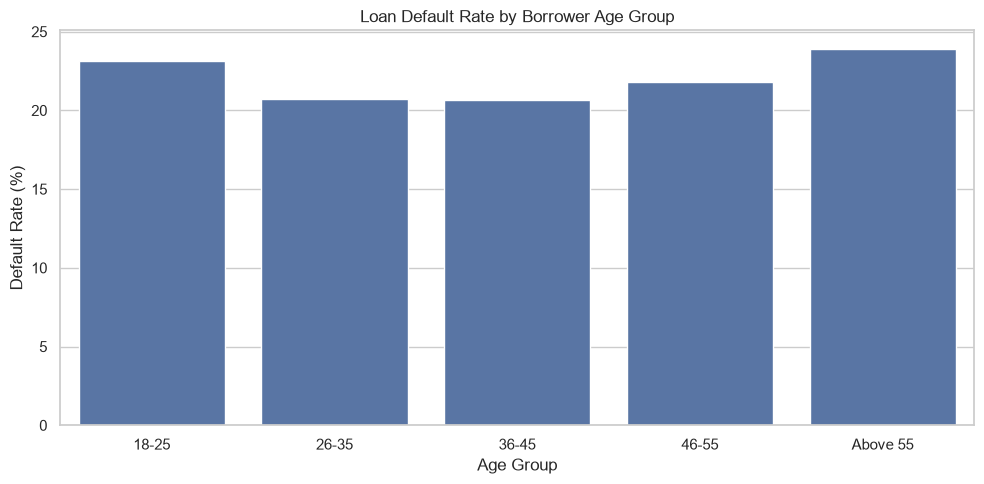

In [7]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=age_analysis.index,
    y=age_analysis["default_rate"]
)

plt.title("Loan Default Rate by Borrower Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "borrower_segmentation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Age-wise Borrower Segmentation – Key Findings

- The dataset contains 32,416 borrowers across five age groups.
- Borrowers aged 18–25 represent the largest segment, with 15,248 borrowers.
- The highest observed default rate is 23.88% among borrowers above 55 years.
- The lowest default rate is 20.68% among borrowers aged 36–45.
- Younger borrowers (18–25) show a default rate of 23.13%.
- Default rates are relatively similar across age groups.
- The above-55 age group has a small sample size of 134 borrowers, so its higher default rate should be interpreted cautiously.

**Business Insight:** Age alone may not be sufficient to determine borrower risk. Income, loan burden, credit history and previous defaults should also be considered.

In [8]:
# Loan burden analysis – initial inspection

print("LOAN BURDEN DISTRIBUTION")
print("=" * 45)

print("\nDescriptive Statistics:")
display(df["loan_percent_income"].describe())

print("\nMissing Values:")
print(df["loan_percent_income"].isnull().sum())

print("\nMinimum Value:")
print(df["loan_percent_income"].min())

print("\nMaximum Value:")
print(df["loan_percent_income"].max())

LOAN BURDEN DISTRIBUTION

Descriptive Statistics:


count    32416.000000
mean         0.170250
std          0.106812
min          0.000000
25%          0.090000
50%          0.150000
75%          0.230000
max          0.830000
Name: loan_percent_income, dtype: float64


Missing Values:
0

Minimum Value:
0.0

Maximum Value:
0.83


In [9]:
# Compare loan burden for default and non-default borrowers

burden_analysis = df.groupby("loan_status").agg(
    total_borrowers=("loan_status", "count"),
    average_loan_burden=("loan_percent_income", "mean"),
    median_loan_burden=("loan_percent_income", "median")
)

burden_analysis.index = [
    "Non-default",
    "Default"
]

display(burden_analysis.round(3))

,total_borrowers,average_loan_burden,median_loan_burden
Non-default,25327,0.149,0.13
Default,7089,0.247,0.24


### Loan Burden Analysis – Key Findings

- The dataset contains 32,416 borrowers with no missing loan burden values.
- The average loan burden across all borrowers is approximately 17.03%.
- The median loan burden is 15%.
- The maximum observed loan burden is 83%.
- Defaulted borrowers have an average loan burden of 24.7%.
- Non-defaulted borrowers have an average loan burden of 14.9%.
- Defaulted borrowers show a higher median loan burden (24%) compared to non-defaulted borrowers (13%).

**Business Insight:** Borrowers with higher loan burdens show a stronger association with loan default. Loan burden can be an important variable for identifying potentially high-risk borrowers.

In [10]:
# Borrower segmentation based on loan burden

df["loan_burden_group"] = pd.cut(
    df["loan_percent_income"],
    bins=[-0.001, 0.10, 0.20, 0.30, 1.0],
    labels=[
        "Low",
        "Moderate",
        "High",
        "Very High"
    ]
)

# Calculate borrower count and default rate

loan_burden_analysis = df.groupby(
    "loan_burden_group",
    observed=False
).agg(
    total_borrowers=("loan_status", "count"),
    default_borrowers=("loan_status", "sum")
)

loan_burden_analysis["default_rate"] = (
    loan_burden_analysis["default_borrowers"] /
    loan_burden_analysis["total_borrowers"] * 100
).round(2)

display(loan_burden_analysis)

,total_borrowers,default_borrowers,default_rate
loan_burden_group,,,
Low,10430,1226,11.75
Moderate,11999,1815,15.13
High,6168,1358,22.02
Very High,3819,2690,70.44


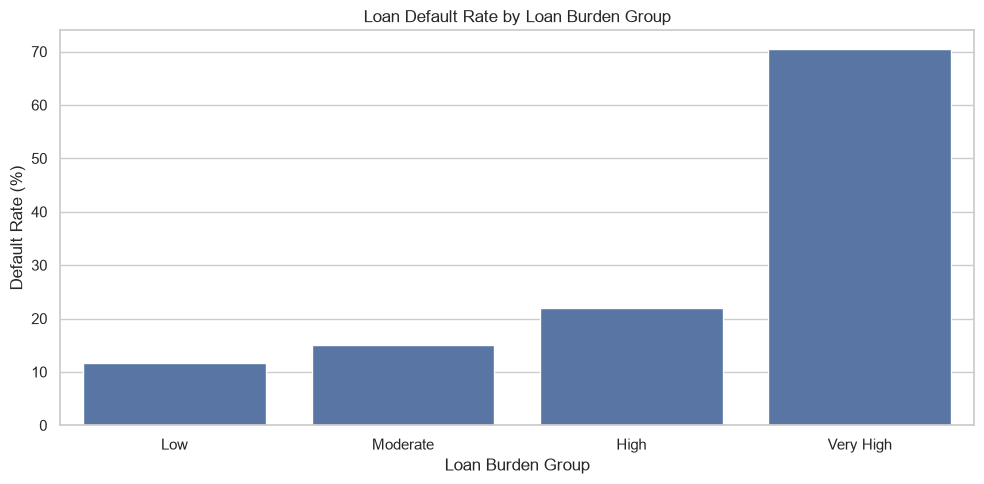

In [11]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=loan_burden_analysis.index,
    y=loan_burden_analysis["default_rate"]
)

plt.title("Loan Default Rate by Loan Burden Group")
plt.xlabel("Loan Burden Group")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "loan_burden_default_rate.png", dpi=300, bbox_inches="tight")

plt.show()

### Loan Burden Segmentation – Key Findings

- Borrowers were divided into four loan burden groups: Low, Moderate, High, and Very High.
- The Low group has a default rate of 11.75%.
- The Moderate group has a default rate of 15.13%.
- The High group has a default rate of 22.02%.
- The Very High group has the highest default rate of 70.44%.
- A total of 2,690 borrowers in the Very High group defaulted.

**Business Insights:**

- Default rates increase as loan burden increases across all four groups.
- Borrowers in the Very High loan burden group show significantly higher default risk.
- Loan burden is an important variable for credit risk assessment.
- The Very High group represents approximately 11.78% of all borrowers but accounts for approximately 37.95% of all defaults.

**Conclusion:** Loan burden segmentation reveals a strong association between higher loan burden and loan default. This information can help identify potentially high-risk borrowers.

## 13. Loan Grade vs Default Rate Analysis

### Objective
To analyze the relationship between loan grades and default rates and identify which loan grades have higher credit risk.

In [12]:
# Analyze borrower count and default rate by loan grade

grade_analysis = df.groupby("loan_grade").agg(
    total_borrowers=("loan_status", "count"),
    default_borrowers=("loan_status", "sum")
)

grade_analysis["default_rate"] = (
    grade_analysis["default_borrowers"] /
    grade_analysis["total_borrowers"] * 100
).round(2)

display(grade_analysis)

,total_borrowers,default_borrowers,default_rate
loan_grade,,,
A,10703,1066,9.96
B,10387,1695,16.32
C,6438,1336,20.75
D,3620,2138,59.06
E,963,621,64.49
F,241,170,70.54
G,64,63,98.44


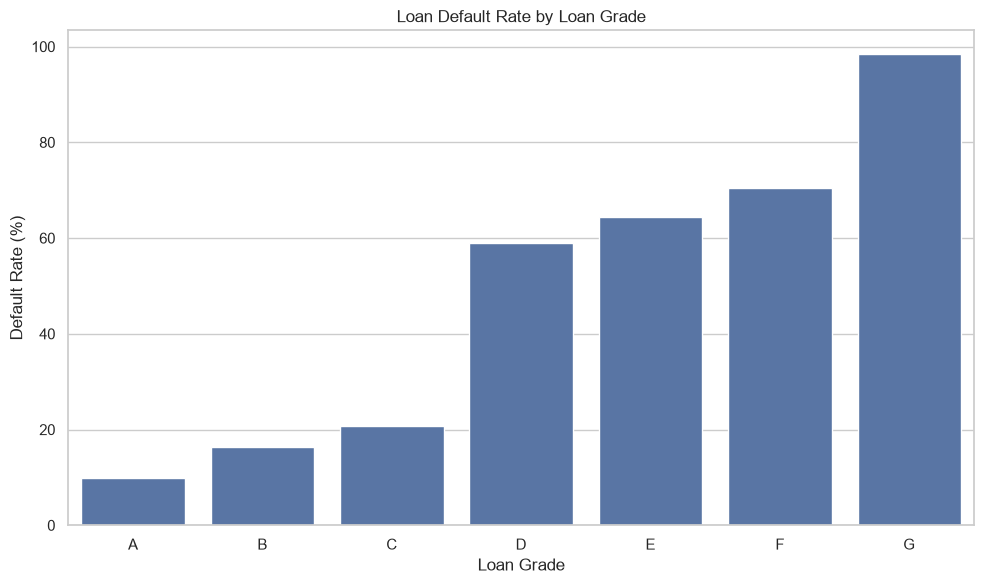

In [13]:
# Visualize default rate by loan grade

plt.figure(figsize=(10, 6))

sns.barplot(
    x=grade_analysis.index,
    y=grade_analysis["default_rate"]
)

plt.title("Loan Default Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "loan_grade_default_rate.png", dpi=300, bbox_inches="tight")

plt.show()

## Loan Grade Analysis – Key Findings

- Loan grades range from A to G.
- Grade A has the lowest default rate of 9.96%.
- Grade B has a default rate of 16.32%.
- Grade C has a default rate of 20.75%.
- Grade D has a default rate of 59.06%.
- Grade E has a default rate of 64.49%.
- Grade F has a default rate of 70.54%.
- Grade G has the highest default rate of 98.44%.

### Business Insights

- Default rates generally increase as loan grades move from A to G.
- Grade A borrowers demonstrate the lowest observed default rate.
- Grade G borrowers demonstrate the highest observed default rate.
- Grade G contains only 64 borrowers, so its default rate should be interpreted cautiously.
- Loan grade is an important factor to consider when assessing credit risk.

### Conclusion

Loan grade analysis shows a strong association between lower loan grades and higher default rates. This information can help financial institutions identify borrowers with potentially higher credit risk.

## 14. Borrower Income vs Loan Default Analysis

### Objective
To analyze borrower income groups and identify how income levels are associated with loan default rates.

In [14]:
# Create borrower income groups

df["income_group"] = pd.qcut(
    df["person_income"],
    q=4,
    labels=["Low Income", "Lower-Middle Income",
            "Upper-Middle Income", "High Income"]
)

# Calculate borrower count and default rate

income_analysis = df.groupby(
    "income_group",
    observed=False
).agg(
    total_borrowers=("loan_status", "count"),
    default_borrowers=("loan_status", "sum"),
    average_income=("person_income", "mean")
)

income_analysis["default_rate"] = (
    income_analysis["default_borrowers"] /
    income_analysis["total_borrowers"] * 100
).round(2)

display(income_analysis.round(2))

,total_borrowers,default_borrowers,average_income,default_rate
income_group,,,,
Low Income,8104,3221,28625.88,39.75
Lower-Middle Income,8188,1753,47046.34,21.41
Upper-Middle Income,8020,1375,66281.66,17.14
High Income,8104,740,122612.06,9.13


### Income-Based Borrower Segmentation – Key Findings

- Borrowers were divided into four income groups.
- The Low Income group has the highest default rate of 39.75%.
- The Lower-Middle Income group has a default rate of 21.41%.
- The Upper-Middle Income group has a default rate of 17.14%.
- The High Income group has the lowest default rate of 9.13%.

**Business Insights:**

- Default rates generally decrease as borrower income increases.
- Low-income borrowers demonstrate higher observed default risk.
- High-income borrowers demonstrate lower observed default risk.
- Income is an important factor for credit risk assessment.

**Conclusion:** Income-based segmentation reveals an inverse association between borrower income and loan default rates. Financial institutions can consider income along with other borrower characteristics when assessing credit risk.

## 15. Home Ownership vs Loan Default Analysis

### Objective

To analyze borrower home ownership categories and identify their relationship with loan default rates.

In [15]:
# Analyze borrower home ownership and loan defaults

home_analysis = df.groupby(
    "person_home_ownership"
).agg(
    total_borrowers=("loan_status", "count"),
    default_borrowers=("loan_status", "sum"),
    average_income=("person_income", "mean")
)

home_analysis["default_rate"] = (
    home_analysis["default_borrowers"] /
    home_analysis["total_borrowers"] * 100
).round(2)

display(home_analysis.round(2))

,total_borrowers,default_borrowers,average_income,default_rate
person_home_ownership,,,,
MORTGAGE,13369,1687,81150.98,12.62
OTHER,106,33,76561.27,31.13
OWN,2563,192,57858.83,7.49
RENT,16378,5177,55019.63,31.61


### Home Ownership Analysis – Key Findings

- Borrowers were divided into four home ownership categories.
- RENT borrowers have the highest default rate of 31.61%.
- OTHER borrowers have a default rate of 31.13%.
- MORTGAGE borrowers have a default rate of 12.62%.
- OWN borrowers have the lowest default rate of 7.49%.
- RENT borrowers account for 5,177 loan defaults.

**Business Insights:**

- Renters demonstrate higher observed loan default rates.
- Borrowers who own their homes show lower observed default rates.
- Home ownership status can provide additional information for credit risk assessment.
- The OTHER category has only 106 borrowers, so its default rate should be interpreted cautiously.

**Conclusion:** Home ownership analysis reveals differences in loan default rates across borrower categories. Financial institutions can consider home ownership status alongside income, loan burden and other financial characteristics when evaluating credit risk.

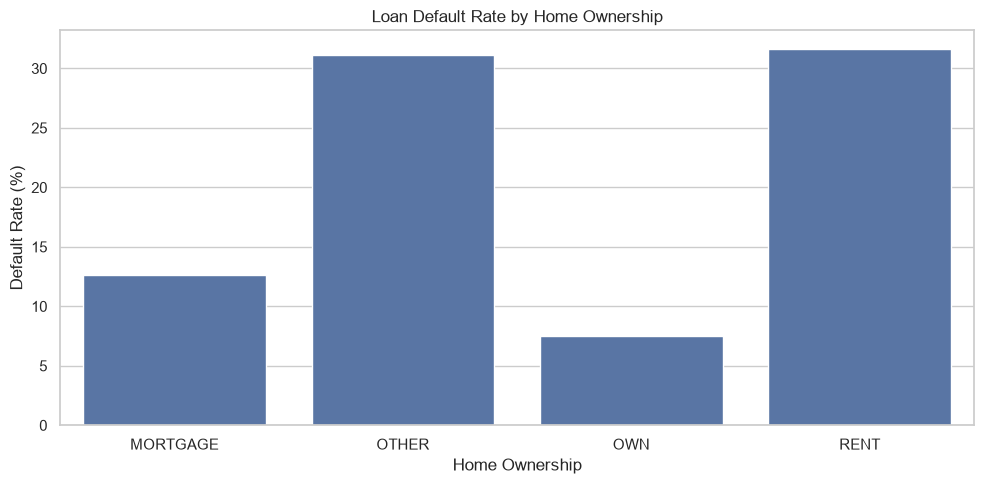

In [16]:
# Visualize loan default rate by home ownership

plt.figure(figsize=(10, 5))

sns.barplot(
    x=home_analysis.index.astype(str),
    y=home_analysis["default_rate"]
)

plt.title("Loan Default Rate by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "home_ownership_default_rate.png", dpi=300, bbox_inches="tight")

plt.show()

## 16. Employment Length vs Loan Default Analysis

### Objective

To analyze borrower employment experience and identify its relationship with loan default rates.

In [17]:
# Analyze employment length and loan defaults

employment_analysis = df.groupby(
    "person_emp_length"
).agg(
    total_borrowers=("loan_status", "count"),
    default_borrowers=("loan_status", "sum"),
    average_income=("person_income", "mean")
)

employment_analysis["default_rate"] = (
    employment_analysis["default_borrowers"] /
    employment_analysis["total_borrowers"] * 100
).round(2)

display(employment_analysis.round(2))

,total_borrowers,default_borrowers,average_income,default_rate
person_emp_length,,,,
0,4094,1145,57882.42,27.97
1,2934,830,59340.90,28.29
2,3963,1052,59548.07,26.55
3,3621,756,62868.43,20.88
4,3052,657,62623.73,21.53
5,3060,582,64002.70,19.02
6,2743,515,64113.13,18.78
7,2246,423,68788.29,18.83
8,1708,288,74352.79,16.86


In [18]:
# Create employment length groups

bins = [-1, 2, 5, 10, 15, float("inf")]

labels = [
    "0-2 Years",
    "3-5 Years",
    "6-10 Years",
    "11-15 Years",
    "16+ Years"
]

df["employment_group"] = pd.cut(
    df["person_emp_length"],
    bins=bins,
    labels=labels
)

# Calculate borrower count and default rate

employment_analysis = df.groupby(
    "employment_group",
    observed=False
).agg(
    total_borrowers=("loan_status", "count"),
    default_borrowers=("loan_status", "sum"),
    average_income=("person_income", "mean")
)

employment_analysis["default_rate"] = (
    employment_analysis["default_borrowers"] /
    employment_analysis["total_borrowers"] * 100
).round(2)

display(employment_analysis.round(2))

,total_borrowers,default_borrowers,average_income,default_rate
employment_group,,,,
0-2 Years,10991,3027,58872.33,27.54
3-5 Years,9733,1995,63148.31,20.50
6-10 Years,8768,1593,70729.03,18.17
11-15 Years,2310,375,88649.36,16.23
16+ Years,614,99,90889.62,16.12


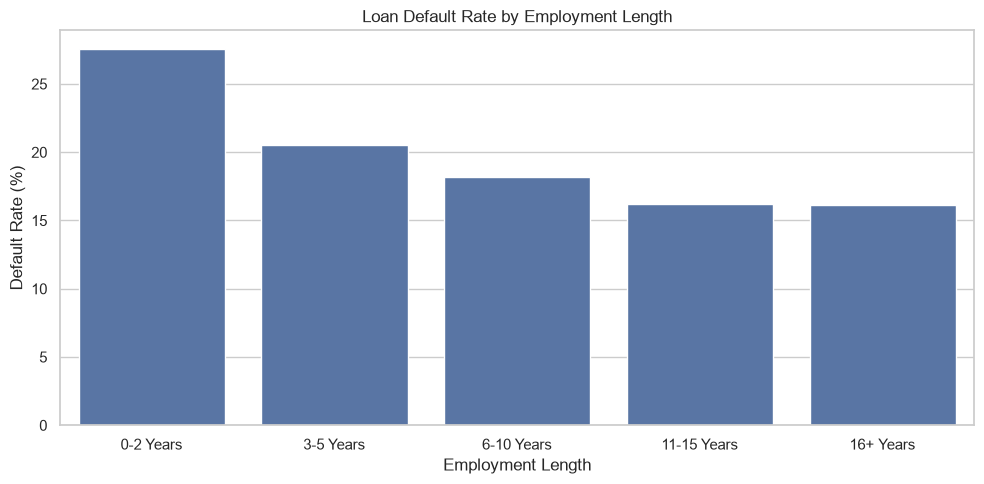

In [19]:
# Visualize default rate by employment length

plt.figure(figsize=(10, 5))

sns.barplot(
    x=employment_analysis.index.astype(str),
    y=employment_analysis["default_rate"]
)

plt.title("Loan Default Rate by Employment Length")
plt.xlabel("Employment Length")
plt.ylabel("Default Rate (%)")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(FIGURES_DIR / "employment_length_default_rate.png", dpi=300, bbox_inches="tight")

plt.show()

## Employment Length Analysis – Key Findings

- Borrowers with 0–2 years of employment have the highest default rate of 27.54%.
- Borrowers with 3–5 years of employment have a default rate of 20.50%.
- Borrowers with 6–10 years of employment have a default rate of 18.17%.
- Borrowers with 11–15 years of employment have a default rate of 16.23%.
- Borrowers with 16+ years of employment have the lowest default rate of 16.12%.

### Business Insights

- Default rates generally decrease as employment length increases.
- Borrowers with shorter employment histories show higher default risk.
- Average borrower income increases across the employment groups.
- Employment length can be considered an important factor in credit risk assessment.

### Conclusion

Employment length analysis indicates an association between employment experience and loan default rates. Borrowers with shorter employment histories demonstrate higher default rates, which may help financial institutions identify potential credit risk.

## Combined Risk View and Business Recommendations

### How to read the combined view

The heatmap compares observed default rates across loan grades and loan-burden groups. Cells with fewer than 50 borrowers are hidden because their rates are based on small samples; the companion count table provides segment sizes. These are descriptive associations in this dataset, not causal effects or validated underwriting thresholds. In the executed results, the Very High burden segment contains 2,690 defaults and has a 70.44% default rate. Within grades A, B, and C, the observed rates rise from 3.83%, 7.49%, and 11.33% in the Low burden group to 60.93%, 66.18%, and 75.47% in the Very High group. Grade G has a 98.44% overall default rate, but represents only 64 borrowers; interpret it cautiously.

### Business recommendations

1. **Review high loan-burden applications more closely.** Default rates rise sharply in the Very High burden group overall. Use burden as a review signal alongside repayment capacity and other verified information, rather than as a stand-alone rejection rule.
2. **Combine risk indicators.** Assess loan grade and loan burden together; the combined table shows how burden differences persist within many grades. Validate the pattern on a later time period before changing credit policy.
3. **Monitor segment sizes and outcomes.** Track default rates, borrower counts, and uncertainty over time. Treat small segments, especially grades F and G, as directional only until more observations are available.
4. **Check fairness and model performance.** Before operational use, test calibration and outcomes across relevant groups, monitor drift, and document governance approval.

### Scope and limitation

This notebook uses a KNN-imputed corrected dataset and reports descriptive rates. Imputation, class balance, data provenance, and the lack of temporal validation can affect these results. The analysis supports investigation and monitoring; it does not establish causation or a production-ready credit decision rule.

Borrower count by loan grade and loan burden:


loan_burden_group,Low,Moderate,High,Very High
loan_grade,,,,
A,4023,4129,1627,924
B,3218,3759,2053,1357
C,2066,2336,1298,738
D,864,1355,854,547
E,204,336,238,185
F,49,65,78,49
G,6,19,20,19


Default rate (%) by loan grade and loan burden:


loan_burden_group,Low,Moderate,High,Very High
loan_grade,,,,
A,3.83,4.82,9.22,60.93
B,7.49,8.11,12.23,66.18
C,11.33,13.23,18.18,75.47
D,51.16,55.06,58.31,82.63
E,59.31,57.74,61.34,86.49
F,59.18,66.15,73.08,83.67
G,83.33,100.00,100.00,100.00


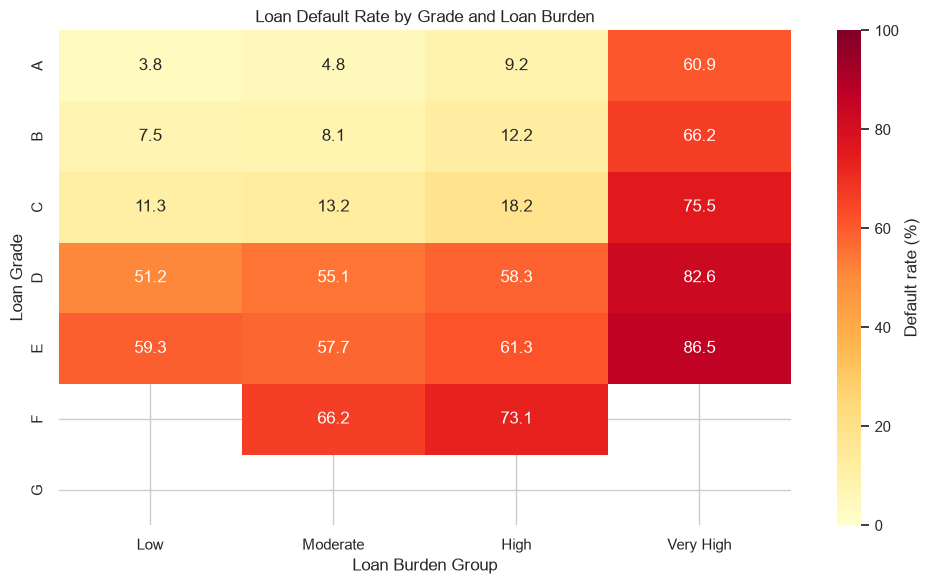

In [20]:
# Combined loan-grade and loan-burden risk analysis

# Recreate the burden groups explicitly so this section runs independently.
burden_labels = ["Low", "Moderate", "High", "Very High"]
df["loan_burden_group"] = pd.cut(
    df["loan_percent_income"],
    bins=[-0.001, 0.10, 0.20, 0.30, 1.0],
    labels=burden_labels
)

grade_burden_summary = df.groupby(
    ["loan_grade", "loan_burden_group"], observed=False
)["loan_status"].agg(total_borrowers="count", default_borrowers="sum")
grade_burden_summary["default_rate"] = (
    grade_burden_summary["default_borrowers"] /
    grade_burden_summary["total_borrowers"] * 100
)

default_rate_matrix = grade_burden_summary["default_rate"].unstack("loan_burden_group")
count_matrix = grade_burden_summary["total_borrowers"].unstack("loan_burden_group")

print("Borrower count by loan grade and loan burden:")
display(count_matrix.astype(int))
print("Default rate (%) by loan grade and loan burden:")
display(default_rate_matrix.round(2))

# Hide cells with fewer than 50 borrowers to avoid over-interpreting small segments.
plt.figure(figsize=(10, 6))
sns.heatmap(
    default_rate_matrix,
    annot=default_rate_matrix.round(1),
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    mask=(count_matrix < 50) | default_rate_matrix.isna(),
    cbar_kws={"label": "Default rate (%)"}
)
plt.title("Loan Default Rate by Grade and Loan Burden")
plt.xlabel("Loan Burden Group")
plt.ylabel("Loan Grade")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "grade_by_loan_burden_default_rate.png", dpi=300, bbox_inches="tight")
plt.show()